# Bangkok CCTV evaluation
Data cover 25–31 August 2026, Bangkok local time. Model metrics apply to candidate vehicle crops from the 450 hand labels. Aggregate sightings count model detections rather than unique vehicles.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

HERE = Path.cwd()
ROOT = HERE.parents[1]
df = pd.read_csv(HERE / "crop_predictions.csv", parse_dates=["timestamp"])
assert len(df) == 450 and df.rid.is_unique
models = [c for c in ("baseline_oof", "clip_linear_oof", "clip_checkpoint_in_sample") if c in df]
assert df.groupby("camera_id").fold.nunique().max() == 1
assert df.fold.nunique() == 5

def metrics(rows, column):
    actual = rows.y4.eq("heavy")
    pred = rows[column].eq("heavy")
    tp = (actual & pred).sum()
    return {
        "n": len(rows), "actual_heavy": int(actual.sum()), "predicted_heavy": int(pred.sum()),
        "accuracy": rows.y4.eq(rows[column]).mean(),
        "heavy_precision": tp / pred.sum() if pred.any() else float("nan"),
        "heavy_recall": tp / actual.sum() if actual.any() else float("nan"),
    }

def graph(table, columns, name, title, xlabel=""):
    ax = table[columns].plot.bar(rot=0, figsize=(8, 4), color=["#00798c", "#edae49", "#505fa5"][:len(columns)])
    ax.set_ylim(0, 1)
    ax.set_title(title, loc="left")
    ax.set_ylabel("Fraction")
    labels = {"accuracy": "Accuracy", "heavy_precision": "Heavy precision", "heavy_recall": "Heavy recall"}
    ax.legend([labels.get(c, c) for c in columns])
    ax.set_xlabel(xlabel)
    ax.figure.tight_layout()
    ax.figure.savefig(HERE / name, dpi=150)
    plt.show()


## Five-fold cross-validation
Five folds keep each camera entirely within a single split. One classifier uses spatial gradient and color features. The other uses the frozen DataComp XL CLIP ViT-B/16 image encoder and fits a fresh logistic regression classifier on the training cameras in each fold. Each crop receives one prediction from a classifier trained on the other four folds. The published project checkpoint was fine-tuned end-to-end using Thai Vehicles and the 450 CCTV labels. Its training-set results are reported separately.

n  actual_heavy  predicted_heavy  accuracy  \
baseline_oof    1  115.0          37.0             36.0     0.400   
                2   64.0          20.0             14.0     0.422   
                3   85.0          19.0             23.0     0.447   
                4   88.0          34.0             34.0     0.398   
                5   98.0          31.0             34.0     0.367   
clip_linear_oof 1  115.0          37.0             46.0     0.600   
                2   64.0          20.0             14.0     0.688   
                3   85.0          19.0             33.0     0.576   
                4   88.0          34.0             28.0     0.580   
                5   98.0          31.0             40.0     0.653   

                   heavy_precision  heavy_recall  
baseline_oof    1            0.417         0.405  
                2            0.500         0.350  
                3            0.391         0.474  
                4            0.412         0.412  
                5            0.412         0.452  
clip_linear_oof 1            0.565         0.703  
                2            0.714         0.500  
                3            0.485         0.842  
                4            0.679         0.559  
                5            0.575         0.742

,n,actual_heavy,predicted_heavy,accuracy,heavy_precision,heavy_recall
baseline_oof,450.0,141.0,141.0,0.404,0.418,0.418
clip_linear_oof,450.0,141.0,161.0,0.616,0.584,0.667


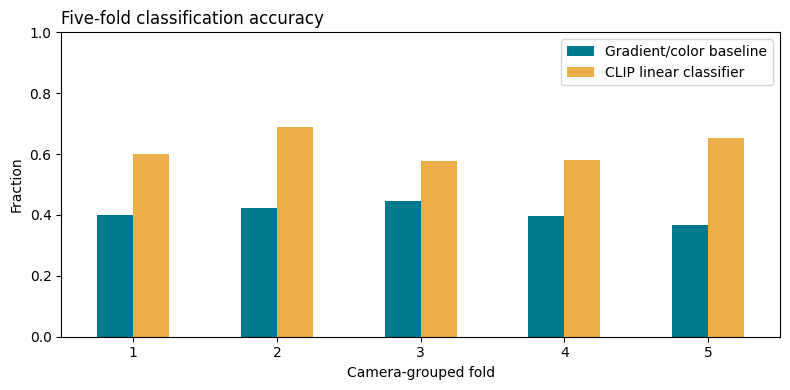

In [2]:
cv_models = ["baseline_oof", "clip_linear_oof"]
cv = pd.DataFrame({
    (model, k): metrics(g, model) for model in cv_models for k, g in df.groupby("fold")
}).T
display(cv.round(3))
display(pd.DataFrame({model: metrics(df, model) for model in cv_models}).T.round(3))
fold_accuracy = cv.accuracy.unstack(level=0).rename(columns={
    "baseline_oof": "Gradient/color baseline",
    "clip_linear_oof": "CLIP linear classifier",
})
graph(fold_accuracy, list(fold_accuracy.columns), "cross_validation.png",
      "Five-fold classification accuracy", "Camera-grouped fold")

## Day and night
Day is 06:00–18:29 Bangkok time. Compare baseline and CLIP linear predictions on held-out cameras and the supplied checkpoint's descriptive training-set predictions. Differences can also reflect the mix of cameras and labeled vehicle classes.

n  actual_heavy  predicted_heavy  \
baseline_oof              Day    417.0         137.0            135.0   
                          Night   33.0           4.0              6.0   
clip_linear_oof           Day    417.0         137.0            157.0   
                          Night   33.0           4.0              4.0   
clip_checkpoint_in_sample Day    417.0         137.0            137.0   
                          Night   33.0           4.0              4.0   

                                 accuracy  heavy_precision  heavy_recall  
baseline_oof              Day       0.396            0.430         0.423  
                          Night     0.515            0.167         0.250  
clip_linear_oof           Day       0.609            0.586         0.672  
                          Night     0.697            0.500         0.500  
clip_checkpoint_in_sample Day       1.000            1.000         1.000  
                          Night     1.000            1.000         1.000

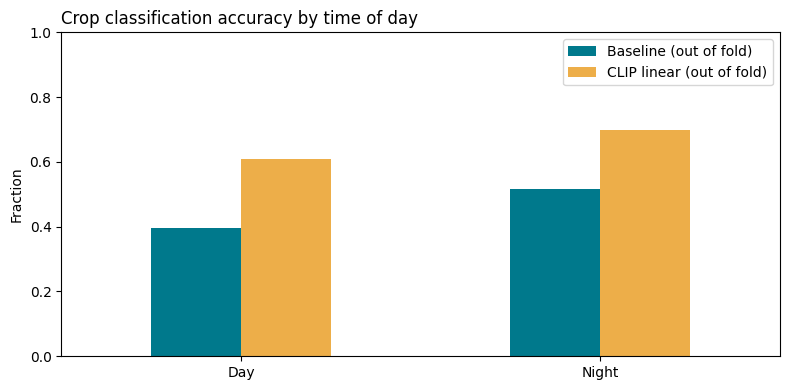

In [3]:
minute = df.timestamp.dt.hour * 60 + df.timestamp.dt.minute
df["light"] = minute.between(360, 1109).map({True: "Day", False: "Night"})
light = pd.DataFrame({
    (model, period): metrics(rows, model)
    for model in models
    for period, rows in df.groupby("light")
}).T
display(light.round(3))
light_accuracy = light.accuracy.unstack(level=0)[cv_models].rename(columns={
    "baseline_oof": "Baseline (out of fold)",
    "clip_linear_oof": "CLIP linear (out of fold)",
})
graph(light_accuracy, list(light_accuracy.columns), "day_night.png", "Crop classification accuracy by time of day")

## Historical precipitation
Source is [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api), ERA5 grid point requested at 13.75°N, 100.50°E. The response is preserved alongside this notebook. Precipitation refers to the preceding hour, so a frame at 13:20 is paired with the 14:00 record. Wet means ≥0.1 mm. One city grid point is a proxy for local conditions at each camera. Rates are exposure-weighted by frame count. The matched comparison reports equal-weight differences in rates within camera, clock hour and weekday/weekend strata observed under both conditions. Traffic patterns and detection errors can both contribute to any observed association.

Matched 10,655 of 10,655 rows


,heavy,frames,sightings_per_100_frames
weather,,,
Dry,6630.0,31438,21.089
Wet,6547.0,29344,22.311


Matched strata: 2,193; wet minus dry: 0.087 sightings per 100 frames


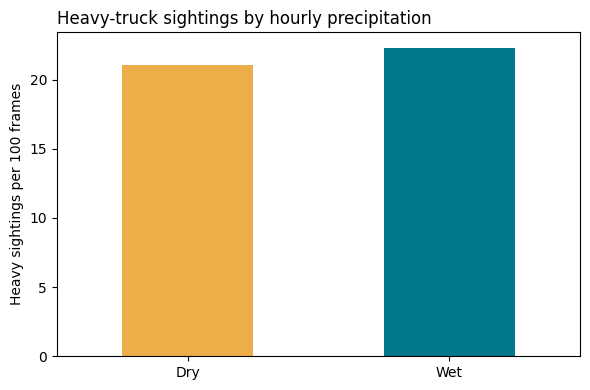

Matched 450 of 450 rows


n  actual_heavy  predicted_heavy  accuracy  \
baseline_oof              Dry  243.0          74.0             78.0     0.424   
                          Wet  207.0          67.0             63.0     0.382   
clip_linear_oof           Dry  243.0          74.0             91.0     0.642   
                          Wet  207.0          67.0             70.0     0.585   
clip_checkpoint_in_sample Dry  243.0          74.0             74.0     1.000   
                          Wet  207.0          67.0             67.0     1.000   

                               heavy_precision  heavy_recall  
baseline_oof              Dry            0.423         0.446  
                          Wet            0.413         0.388  
clip_linear_oof           Dry            0.604         0.743  
                          Wet            0.557         0.582  
clip_checkpoint_in_sample Dry            1.000         1.000  
                          Wet            1.000         1.000

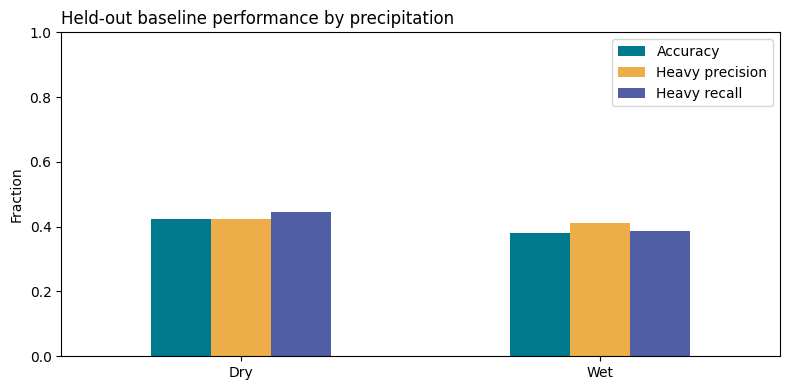

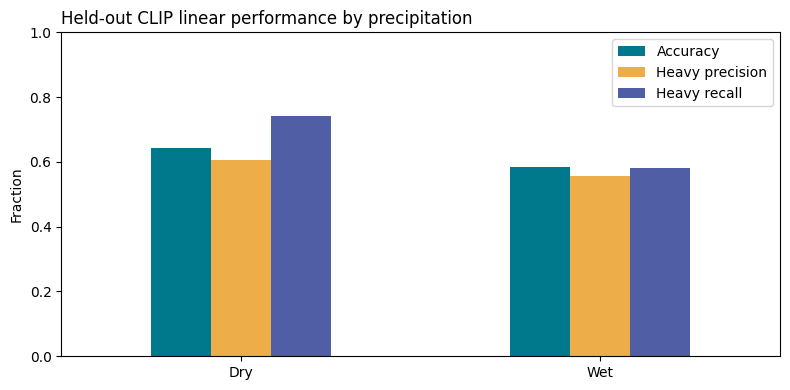

In [4]:
weather = pd.DataFrame(json.loads((HERE / "bangkok_era5.json").read_text())["hourly"])
weather.index = pd.to_datetime(weather.pop("time"))
assert weather.index.is_unique and weather.precipitation.notna().all()

def attach_weather(table, times):
    table = table.copy()
    table["mm"] = (times.dt.floor("h") + pd.Timedelta(hours=1)).map(weather.precipitation)
    table["weather"] = table.mm.ge(0.1).map({True: "Wet", False: "Dry"}).where(table.mm.notna())
    print(f"Matched {table.mm.notna().sum():,} of {len(table):,} rows")
    return table

agg = pd.read_csv(ROOT / "data_out/agg_camera_hour.csv")
agg = attach_weather(agg, pd.to_datetime(agg.date) + pd.to_timedelta(agg.hour, unit="h"))
pooled = agg.groupby("weather")[["heavy", "frames"]].sum()
pooled["sightings_per_100_frames"] = 100 * pooled.heavy / pooled.frames
display(pooled.round(3))
strata = agg.groupby(["camera_id", "hour", "weekday", "weather"])[["heavy", "frames"]].sum()
paired = (100 * strata.heavy / strata.frames).unstack("weather").dropna()
print(f"Matched strata: {len(paired):,}; wet minus dry: {(paired.Wet - paired.Dry).mean():.3f} sightings per 100 frames")

ax = pooled.sightings_per_100_frames.plot.bar(rot=0, color=["#edae49", "#00798c"], figsize=(6, 4))
ax.set_title("Heavy-truck sightings by hourly precipitation", loc="left")
ax.set_ylabel("Heavy sightings per 100 frames")
ax.set_xlabel("")
ax.figure.tight_layout()
ax.figure.savefig(HERE / "rain_sightings.png", dpi=150)
plt.show()

weather_labels = attach_weather(df, df.timestamp)
rain_metrics = pd.DataFrame({
    (model, label): metrics(rows, model)
    for model in models
    for label, rows in weather_labels.groupby("weather")
}).T
display(rain_metrics.round(3))
graph(rain_metrics.loc["baseline_oof"], ["accuracy", "heavy_precision", "heavy_recall"], "rain_baseline_quality.png", "Held-out baseline performance by precipitation")
graph(rain_metrics.loc["clip_linear_oof"], ["accuracy", "heavy_precision", "heavy_recall"], "rain_clip_quality.png", "Held-out CLIP linear performance by precipitation")
